In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/processed/comepleted_parking_sessions.csv', parse_dates=['entry_time','exit_time'])
df.head()

,record_id,location_id,entry_time,exit_time,vehicle_type,recorded_duration,is_season_vehicle,is_normal_vehicle,vehicle_status,parking_slot,...,is_valid_timestamp,is_zero_duration,is_positive_duration,session_status,duration_hours,entry_day,entry_month,day_of_week,is_weekend,exit_hour
0,239854,1,2023-08-07 12:11:38.115638,2023-08-07 18:50:41.155646,2,399.050000,1,1,5,0,...,True,False,True,completed,6.650844,7,8,0,0,18
1,239878,1,2023-08-07 14:42:38.504172,2023-08-07 15:03:47.749831,1,21.150000,1,1,7,0,...,True,False,True,completed,0.352568,7,8,0,0,15
2,239904,1,2023-08-07 16:38:00.409214,2023-08-07 17:23:29.422259,1,45.483333,1,1,5,0,...,True,False,True,completed,0.758059,7,8,0,0,17
3,240110,1,2023-08-08 17:17:31.673766,2023-08-08 18:21:26.912024,2,63.916667,1,1,7,0,...,True,False,True,completed,1.065344,8,8,1,0,18
4,240115,1,2023-08-08 17:54:24.409214,2023-08-08 17:55:02.155484,1,0.616667,1,1,2,0,...,True,False,True,completed,0.010485,8,8,1,0,17


In [3]:
print("First Entry Time:", df['entry_time'].min())
print("Last Entry Time:", df['entry_time'].max())

print("First Exit Time:", df['exit_time'].min())
print("Last Exit Time:", df['exit_time'].max())


First Entry Time: 2023-08-07 12:11:38.115638
Last Entry Time: 2024-05-08 23:29:22.482404
First Exit Time: 2023-08-07 15:03:47.749831
Last Exit Time: 2024-05-08 23:51:49.835074


In [4]:
arrivals =pd.DataFrame({"event_name":df['entry_time'],"arrivals":1,"depatures":0})
departures =pd.DataFrame({"event_name":df['exit_time'],"arrivals":0,"depatures":1})
events = pd.concat([arrivals,departures],ignore_index=True)
events['intervals'] = events['event_name'].dt.floor('15min')
interval_events = events.groupby("intervals")[['arrivals','depatures']].sum()

interval_events.head()



,arrivals,depatures
intervals,,
2023-08-07 12:00:00,1,0
2023-08-07 14:30:00,1,0
2023-08-07 15:00:00,0,1
2023-08-07 16:30:00,1,0
2023-08-07 17:15:00,0,1


In [5]:
# Generate a continuous 15-minute index
full_index = pd.date_range(
    start=interval_events.index.min(),
    end=interval_events.index.max(),
    freq="15min"
)

occupancy_df = interval_events.reindex(
    full_index,
    fill_value=0
)

occupancy_df.index.name = "interval"

# Calculate occupancy using cumulative arrivals and departures
occupancy_df["occupancy"] = (
    occupancy_df["arrivals"]
    - occupancy_df["depatures"]
).cumsum()

# Use interval-end timestamps
occupancy_df = occupancy_df.reset_index()

occupancy_df["timestamp"] = (
    occupancy_df["interval"] + pd.Timedelta(minutes=15)
)

occupancy_df = occupancy_df.drop(columns=["interval"])

occupancy_df.head(10)

,arrivals,depatures,occupancy,timestamp
0,1,0,1,2023-08-07 12:15:00
1,0,0,1,2023-08-07 12:30:00
2,0,0,1,2023-08-07 12:45:00
3,0,0,1,2023-08-07 13:00:00
4,0,0,1,2023-08-07 13:15:00
5,0,0,1,2023-08-07 13:30:00
6,0,0,1,2023-08-07 13:45:00
7,0,0,1,2023-08-07 14:00:00
8,0,0,1,2023-08-07 14:15:00
9,0,0,1,2023-08-07 14:30:00


In [6]:
print("Occupancy dataset shape:", occupancy_df.shape)

print("\nMissing values:")
print(occupancy_df.isnull().sum())

print("\nOccupancy statistics:")
print(occupancy_df["occupancy"].describe())

print("\nNegative occupancy intervals:")
print(
    (occupancy_df["occupancy"] < 0).sum()
)

print("\nMinimum occupancy:")
print(occupancy_df["occupancy"].min())


Occupancy dataset shape: (26448, 4)

Missing values:
arrivals     0
depatures    0
occupancy    0
timestamp    0
dtype: int64

Occupancy statistics:
count    26448.000000
mean        52.480339
std         76.559406
min          0.000000
25%          1.000000
50%         10.000000
75%         93.000000
max        449.000000
Name: occupancy, dtype: float64

Negative occupancy intervals:
0

Minimum occupancy:
0


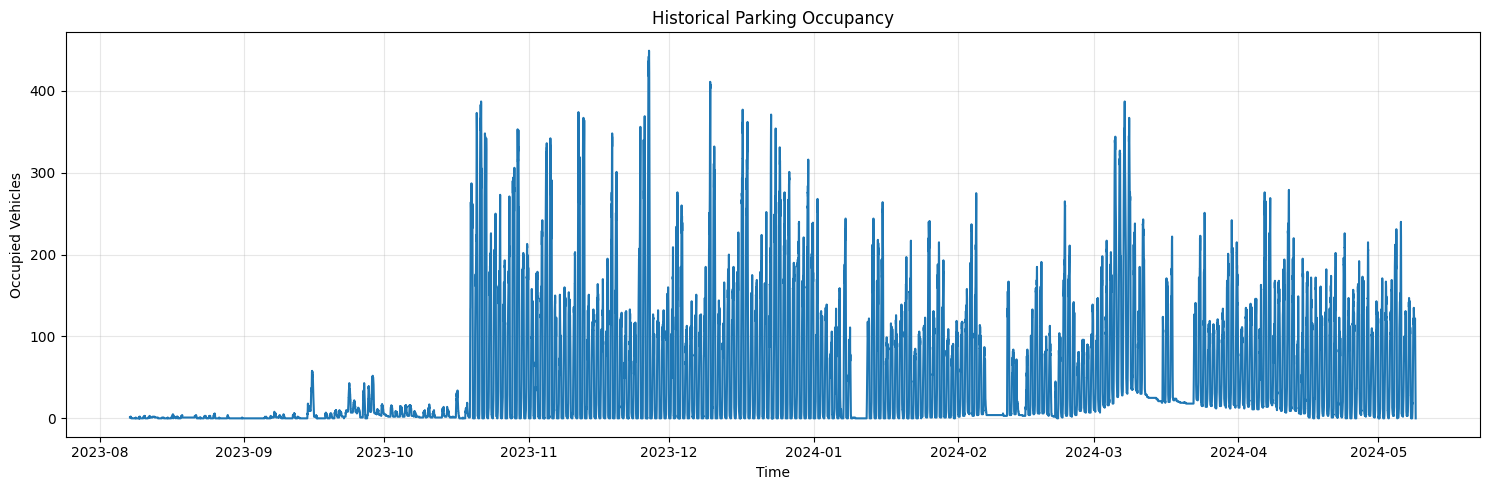

In [7]:
plt.figure(figsize=(15, 5))

plt.plot(
    occupancy_df["timestamp"],
    occupancy_df["occupancy"]
)

plt.title("Historical Parking Occupancy")
plt.xlabel("Time")
plt.ylabel("Occupied Vehicles")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
occupancy_df['hour'] = occupancy_df['timestamp'].dt.hour
occupancy_df['day_of_week'] = occupancy_df['timestamp'].dt.dayofweek
occupancy_df['day_of_month'] =occupancy_df['timestamp'].dt.day
occupancy_df['month'] = occupancy_df['timestamp'].dt.month
occupancy_df['is_weekend'] = (occupancy_df['day_of_week']>=5).astype(int)
occupancy_df['is_business_hour'] = ((occupancy_df['hour']>=9) & (occupancy_df['hour']<=17)).astype(int)
occupancy_df.head()

,arrivals,depatures,occupancy,timestamp,hour,day_of_week,day_of_month,month,is_weekend,is_business_hour
0,1,0,1,2023-08-07 12:15:00,12,0,7,8,0,1
1,0,0,1,2023-08-07 12:30:00,12,0,7,8,0,1
2,0,0,1,2023-08-07 12:45:00,12,0,7,8,0,1
3,0,0,1,2023-08-07 13:00:00,13,0,7,8,0,1
4,0,0,1,2023-08-07 13:15:00,13,0,7,8,0,1


In [9]:
occupancy_df['hour_sin']=np.sin(2*np.pi*occupancy_df['hour']/24)
occupancy_df['hour_cos']=np.cos(2*np.pi*occupancy_df['hour']/24)
occupancy_df['day_sin'] = np.sin(2*np.pi*occupancy_df['day_of_week']/7)
occupancy_df['day_cos'] = np.cos(2*np.pi*occupancy_df['day_of_week']/7)
occupancy_df.head()


,arrivals,depatures,occupancy,timestamp,hour,day_of_week,day_of_month,month,is_weekend,is_business_hour,hour_sin,hour_cos,day_sin,day_cos
0,1,0,1,2023-08-07 12:15:00,12,0,7,8,0,1,1.224647e-16,-1.000000,0.0,1.0
1,0,0,1,2023-08-07 12:30:00,12,0,7,8,0,1,1.224647e-16,-1.000000,0.0,1.0
2,0,0,1,2023-08-07 12:45:00,12,0,7,8,0,1,1.224647e-16,-1.000000,0.0,1.0
3,0,0,1,2023-08-07 13:00:00,13,0,7,8,0,1,-2.588190e-01,-0.965926,0.0,1.0
4,0,0,1,2023-08-07 13:15:00,13,0,7,8,0,1,-2.588190e-01,-0.965926,0.0,1.0


In [10]:
lag_periods =[1,2,4,8,96,672]

for period in lag_periods:
    occupancy_df[f'occupancy_lag_{period}'] = occupancy_df['occupancy'].shift(period)

In [11]:
occupancy_df['rolling_mean_1h'] = (occupancy_df['occupancy'].shift(1).rolling(window=4).mean())
occupancy_df['rolling_mean_3h'] = (occupancy_df['occupancy'].shift(1).rolling(window=12).mean())
occupancy_df['rolling_mean_24h'] = (occupancy_df['occupancy'].shift(1).rolling(window=96).mean())
occupancy_df['rolling_std_1h'] = occupancy_df['occupancy'].shift(1).rolling(window=96).std()

In [12]:
occupancy_df["target_30min"] = (
    occupancy_df["occupancy"].shift(-2)
)

occupancy_df["target_60min"] = (
    occupancy_df["occupancy"].shift(-4)
)

occupancy_df["target_120min"] = (
    occupancy_df["occupancy"].shift(-8)
)

In [13]:
target_columns = [
    "target_30min",
    "target_60min",
    "target_120min"
]

feature_columns = [
    "occupancy",
    "arrivals",
    "depatures",
    "hour",
    "day_of_week",
    "day_of_month",
    "month",
    "is_weekend",
    "is_business_hour",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos",
    "occupancy_lag_1",
    "occupancy_lag_2",
    "occupancy_lag_4",
    "occupancy_lag_8",
    "occupancy_lag_96",
    "occupancy_lag_672",
    "rolling_mean_1h",
    "rolling_mean_3h",
    "rolling_mean_24h",
    "rolling_std_1h"
]

model_df = occupancy_df.dropna(
    subset=feature_columns + target_columns
).copy()

print("Final modelling dataset:", model_df.shape)

model_df.head()

Final modelling dataset: (25768, 27)


,arrivals,depatures,occupancy,timestamp,hour,day_of_week,day_of_month,month,is_weekend,is_business_hour,...,occupancy_lag_8,occupancy_lag_96,occupancy_lag_672,rolling_mean_1h,rolling_mean_3h,rolling_mean_24h,rolling_std_1h,target_30min,target_60min,target_120min
672,0,0,1,2023-08-14 12:15:00,12,0,14,8,0,1,...,1.0,0.0,1.0,1.0,1.0,0.145833,0.354792,1.0,1.0,1.0
673,0,0,1,2023-08-14 12:30:00,12,0,14,8,0,1,...,1.0,0.0,1.0,1.0,1.0,0.156250,0.364998,1.0,1.0,1.0
674,0,0,1,2023-08-14 12:45:00,12,0,14,8,0,1,...,1.0,0.0,1.0,1.0,1.0,0.166667,0.374634,1.0,1.0,1.0
675,0,0,1,2023-08-14 13:00:00,13,0,14,8,0,1,...,1.0,0.0,1.0,1.0,1.0,0.177083,0.383743,1.0,1.0,1.0
676,0,0,1,2023-08-14 13:15:00,13,0,14,8,0,1,...,1.0,0.0,1.0,1.0,1.0,0.187500,0.392361,1.0,1.0,1.0


In [14]:
from pathlib import Path

output_path = Path("../data/synthetic/occupancy_modeling_dataset.csv")

model_df.to_csv(output_path, index=False)